# 02 · Exploratory Data Analysis (EDA)
**Cross-Platform Social Media Trend Intelligence & Prediction System**

Univariate, platform, category, engagement, sentiment, correlation and
trend analysis on the processed dataset.

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv(os.path.join('..', 'dataset', 'processed_social_media_trends.csv'), parse_dates=['date'])
df.shape

(8000, 15)

## 1. Univariate Analysis

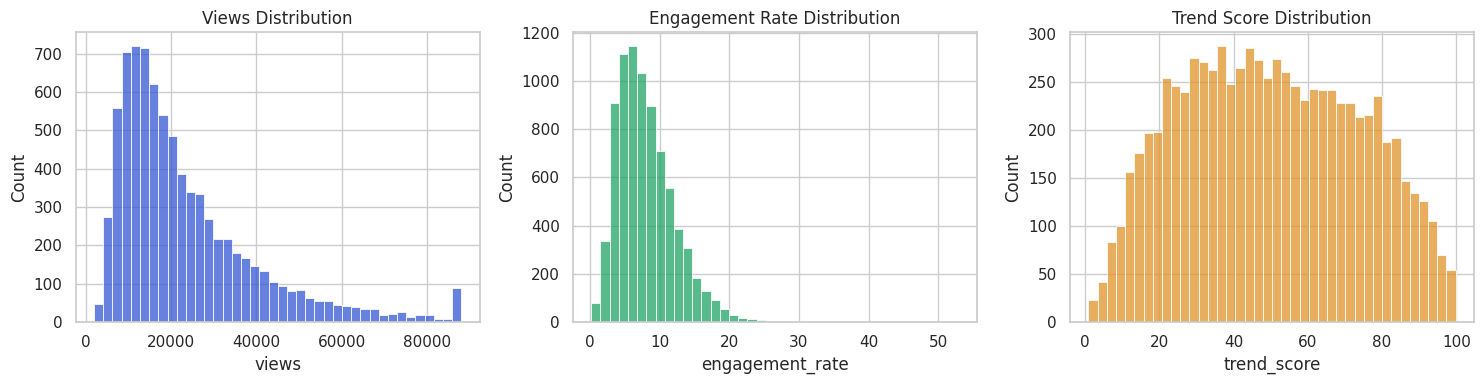

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['views'], bins=40, ax=axes[0], color='#3457D5').set_title('Views Distribution')
sns.histplot(df['engagement_rate'], bins=40, ax=axes[1], color='#21A366').set_title('Engagement Rate Distribution')
sns.histplot(df['trend_score'], bins=40, ax=axes[2], color='#E0932A').set_title('Trend Score Distribution')
plt.tight_layout()
plt.show()

## 2. Platform Analysis

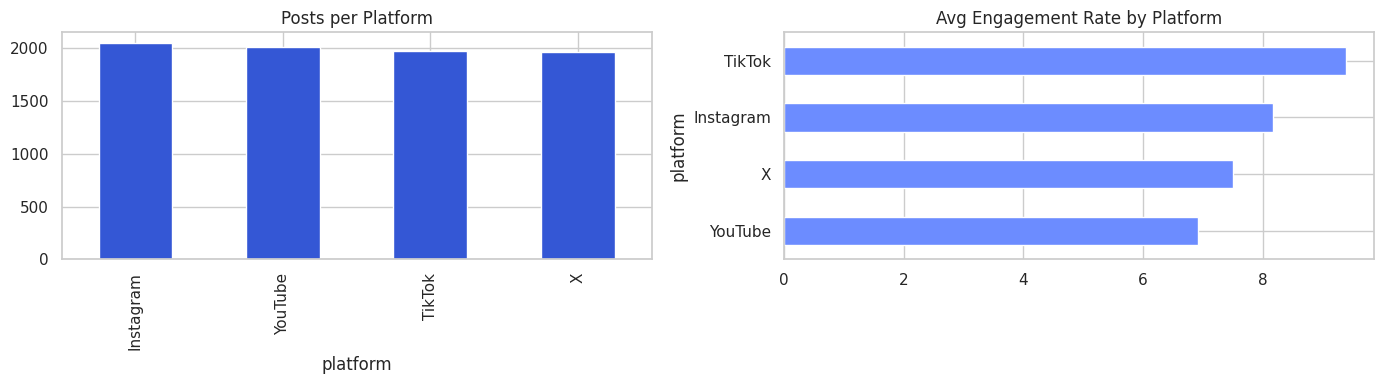

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['platform'].value_counts().plot(kind='bar', ax=axes[0], color='#3457D5')
axes[0].set_title('Posts per Platform')
df.groupby('platform')['engagement_rate'].mean().sort_values().plot(kind='barh', ax=axes[1], color='#6C8CFF')
axes[1].set_title('Avg Engagement Rate by Platform')
plt.tight_layout()
plt.show()

## 3. Category Analysis

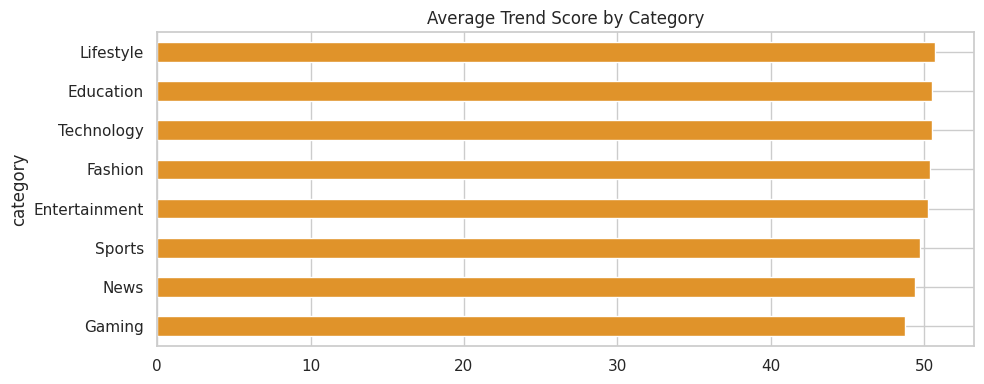

In [4]:
plt.figure(figsize=(10,4))
df.groupby('category')['trend_score'].mean().sort_values().plot(kind='barh', color='#E0932A')
plt.title('Average Trend Score by Category')
plt.tight_layout()
plt.show()

## 4. Engagement Analysis

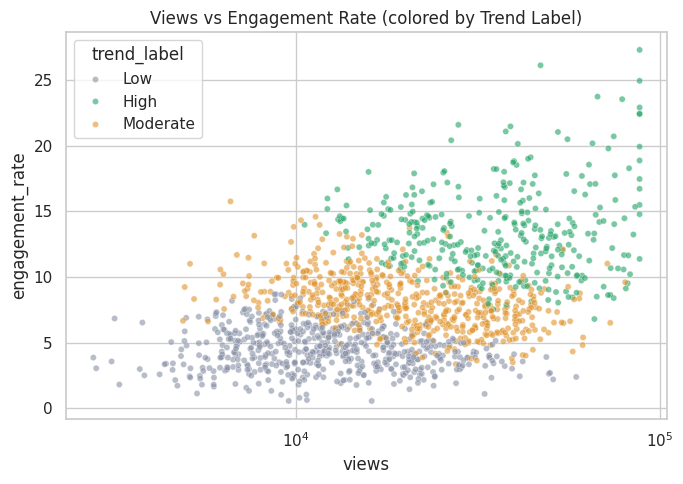

In [5]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df.sample(1500, random_state=42), x='views', y='engagement_rate',
                 hue='trend_label', palette={'Low':'#8890A6','Moderate':'#E0932A','High':'#21A366'}, alpha=0.6, s=20)
plt.xscale('log')
plt.title('Views vs Engagement Rate (colored by Trend Label)')
plt.tight_layout()
plt.show()

## 5. Sentiment Analysis

/tmp/ipykernel_349/44242900.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sentiment', y='trend_score', ax=axes[1],


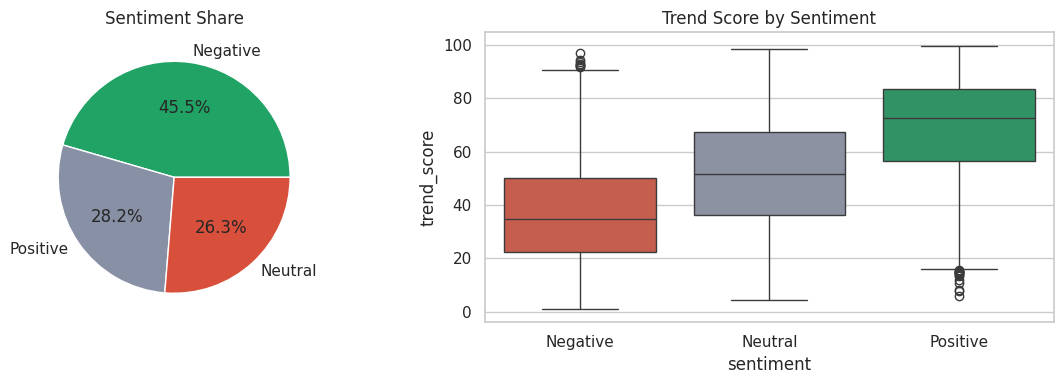

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
df['sentiment'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=axes[0],
                                     colors=['#21A366','#8890A6','#D8503C'])
axes[0].set_ylabel('')
axes[0].set_title('Sentiment Share')
sns.boxplot(data=df, x='sentiment', y='trend_score', ax=axes[1],
            order=['Negative','Neutral','Positive'], palette=['#D8503C','#8890A6','#21A366'])
axes[1].set_title('Trend Score by Sentiment')
plt.tight_layout()
plt.show()

## 6. Correlation Analysis

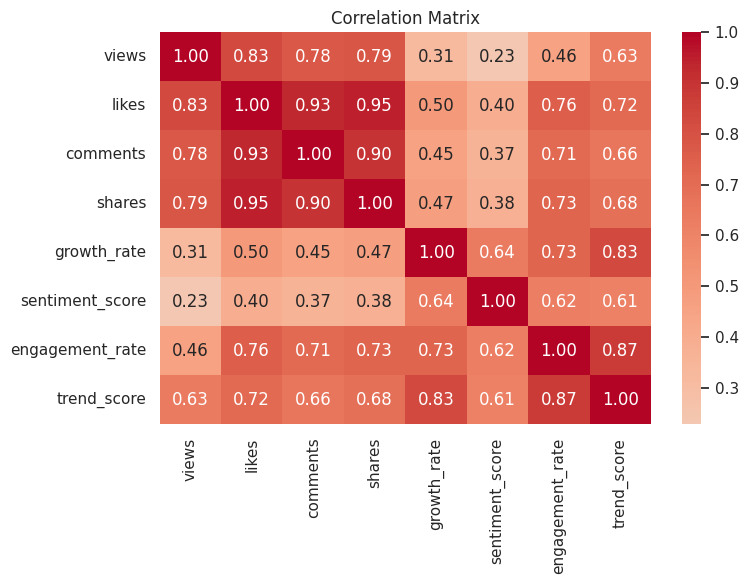

In [7]:
numeric_cols = ['views','likes','comments','shares','growth_rate','sentiment_score','engagement_rate','trend_score']
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

## 7. Trend Analysis Over Time

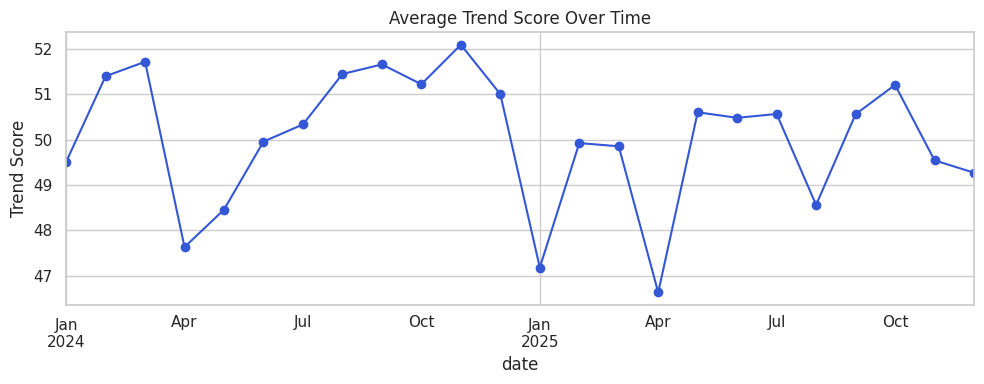

In [8]:
monthly_trend = df.set_index('date').resample('MS')['trend_score'].mean()
plt.figure(figsize=(10,4))
monthly_trend.plot(marker='o', color='#3457D5')
plt.title('Average Trend Score Over Time')
plt.ylabel('Trend Score')
plt.tight_layout()
plt.show()

## 8. Trend Label Distribution

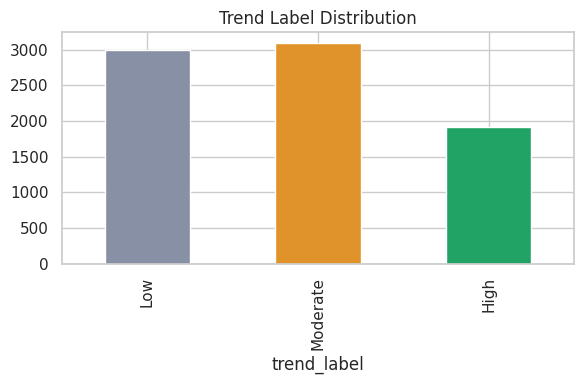

In [9]:
plt.figure(figsize=(6,4))
df['trend_label'].value_counts().reindex(['Low','Moderate','High']).plot(
    kind='bar', color=['#8890A6','#E0932A','#21A366'])
plt.title('Trend Label Distribution')
plt.tight_layout()
plt.show()

## Summary of Key Observations
- Views and engagement are right-skewed, typical of social-media reach data.
- TikTok/YouTube show different engagement dynamics than X/Instagram, consistent with platform-level differences built into the dataset.
- Sentiment correlates positively with trend score — more positive posts trend higher, on average.
- `likes`, `engagement_rate` and `growth_rate` are the numeric features most correlated with `trend_score`, which lines up with the Trend Score formula and previews the feature importance seen later in the Random Forest model.